# Scalar NSI and decoherence at DUNE

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arnavk23/GLoBES.jl/blob/main/notebooks/02_scalar_NSI_and_decoherence_at_DUNE.ipynb)

This notebook uses GLoBES.jl to look at two effects at DUNE: scalar non-standard interactions (SNSI) and environmental decoherence.

- **Scalar NSI** add a Hermitian correction to the neutrino mass matrix, $M \to U\,\mathrm{diag}(m_i)\,U^\dagger + \sqrt{|\Delta m^2_{31}|}\,\eta$.
- **Decoherence** damps the interference between the propagation eigenstates by $e^{-\Gamma L}$, with $\Gamma = \Gamma_0 (E/\mathrm{GeV})^n$.

The model is described by the files in `examples/models/SNSI`, and DUNE by the GLoBES configuration of its Technical Design Report (`dune_configuration()`). The true parameters are those of Table I of the C GLoBES analysis: NuFIT 5.3, $\eta = 0.1$, $\Gamma_0 = 10^{-23}$ GeV, and 5 + 5 years.

On Colab, choose **Runtime → Change runtime type → Julia** first.

In [ ]:
# Install GLoBES.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if both are already installed.
using Pkg
Pkg.add(url = "https://github.com/arnavk23/GLoBES.jl")
Pkg.add("Plots")

In [2]:
using GLoBES, Plots
paper_theme!()   # Plots defaults for publication figures
examples = joinpath(pkgdir(GLoBES), "examples")

"/root/.julia/packages/GLoBES/examples"

## The model files

`SNSI.m` holds the ingredients of the Hamiltonian, one assignment each, with a comment above each one. `parameters.m` holds the parameters, and `Run.m` says what to calculate. Every ingredient that is left out keeps its standard default.

In [3]:
snsi_dir = joinpath(examples, "models", "SNSI")
print(read(joinpath(snsi_dir, "SNSI.m"), String))

(* Scalar non-standard interactions (NSI) and decoherence at long-baseline experiments, in GLoBES.jl. *)
(* Main model file: the ingredients of the effective Hamiltonian
       H = M M^dagger / 2E + A Diag[{1, 0, 0}]
   and the damping of the coherences by decoherence. Every ingredient that is left out takes its default. *)

Model`Name = "SNSI";
Model`NameLaTeX = "Scalar NSI with decoherence";
Model`Authors = "GLoBES.jl example";
Model`Date = "2026-10-24";

(* Mixing matrix in vacuum. The default is the PDG parametrisation, written with the built-in rotations
   R12 = Rotation[1, 2, theta12], R13, R23 and Ud = PhaseMatrix[3, deltaCP]; it is repeated here to show the form. *)

MixingMatrix = R23 . Ud . R13 . Conj[Ud] . R12;

(* Absolute masses. Each MassHierarchy entry: {name, {masses as rules}}. The defaults are
   NH: m1 -> mlightest and IH: m3 -> mlightest, the others from dm21 and dm31; the hierarchy follows the sign of dm31.
   Both are left out here, so the defaults are used. *)



In [4]:
model = load_model(snsi_dir)

OscillationModel "SNSI" by GLoBES.jl example
  flavours:   e, mu, tau
  MixingMatrix                Dot[R23, Ud, R13, Conj[Ud], R12]
  MassMatrix                  Plus[Dot[U, Diag[{m1, m2, m3}], Dagger[U]], Tim...
  AdditionalTerms[Matter]     Times[A, Diag[{1, 0, 0}]]
  Decoherence                 Times[Gamma0, Power[Times[E, Power[GeV, -1]], n]]
  MassHierarchy[NH]           (default)
  MassHierarchy[IH]           (default)
  hierarchy:  Auto
  parameters: theta12, theta13, theta23, deltaCP, dm21, dm31, mlightest, eta_ee, eta_emu, eta_etau, eta_mumu, eta_mutau, eta_tautau, delta_emu, delta_etau, delta_mutau, Gamma0, n

In [5]:
model_parameters(model)   # name, key in OscParams, default, LaTeX name, unit and range of each parameter

18-element Vector{GLoBES.ModelParameter}:
 GLoBES.ModelParameter(:theta12, :θ12, 0.5892020052962348, "\\theta_{12}", "°", nothing, "", :nufit)
 GLoBES.ModelParameter(:theta13, :θ13, 0.15053455433351082, "\\theta_{13}", "°", nothing, "", :nufit)
 GLoBES.ModelParameter(:theta23, :θ23, 0.7553801341748091, "\\theta_{23}", "°", nothing, "", :nufit)
 GLoBES.ModelParameter(:deltaCP, :δ, 3.612831551628262, "\\delta_{\\mathrm{CP}}", "°", nothing, "", :nufit)
 GLoBES.ModelParameter(:dm21, :Δm21, 7.537e-5, "\\Delta m^2_{21}", "eV²", nothing, "", :nufit)
 GLoBES.ModelParameter(:dm31, :Δm31, 0.002521, "\\Delta m^2_{31}", "eV²", nothing, "", :nufit)
 GLoBES.ModelParameter(:mlightest, :m_lightest, 0.0, "m_{\\mathrm{lightest}}", "eV", nothing, "", :default)
 GLoBES.ModelParameter(:eta_ee, :η_ee, 0.0, "\\eta_{ee}", "", (-0.2, 0.2), "", :file)
 GLoBES.ModelParameter(:eta_emu, :η_eμ, 0.0, "\\eta_{e\\mu}", "", (-0.3, 0.3), "", :file)
 GLoBES.ModelParameter(:eta_etau, :η_eτ, 0.0, "\\eta_{e\\tau}", "", (-0.

## True parameters (Table I)

The model's own parameter names (`theta12`, `eta_etau`, `Gamma0`, …) work as keywords. $\Gamma_0$ is given in eV: $10^{-23}$ GeV is $10^{-14}$ eV.

In [6]:
use_model!(model)   # all probabilities and experiments use the SNSI Hamiltonian from now on
table1 = (theta12 = asin(sqrt(0.307)), theta13 = asin(sqrt(0.02203)), theta23 = asin(sqrt(0.572)), deltaCP = deg2rad(198), dm21 = 7.41e-5, dm31 = 2.512e-3)
sm   = OscParams(model; table1...)
nsi  = OscParams(model; table1..., eta_etau = 0.1)
deco = OscParams(model; table1..., Gamma0 = 1e-23 * 1e9)
both = OscParams(model; table1..., eta_etau = 0.1, Gamma0 = 1e-23 * 1e9)
nsi

OscParams
  θ12 = 0.587252  (sin²θ12 = 0.307)
  θ13 = 0.148976  (sin²2θ13 = 0.0861787)
  θ23 = 0.857649  (sin²θ23 = 0.572)
  δ   = 3.45575  (1.1 π)
  Δm21 = 7.41e-05 eV²
  Δm31 = 0.002512 eV²
  m_lightest = 0
  η_ee = 0
  η_eμ = 0
  η_eτ = 0.1
  η_μμ = 0
  η_μτ = 0
  η_ττ = 0
  δ_eμ = 0
  δ_eτ = 0
  δ_μτ = 0
  Gamma0 = 0
  n = 0
  ρ   = 1.0

## Probabilities at 1300 km

In [7]:
[probability(p, :μ, :e; E = 2.5, L = 1300, ρ = 2.848) for p in (sm, nsi, deco, both)]   # P(νμ → νe) at 2.5 GeV: SM, η, Γ, both

4-element Vector{Float64}:
 0.07896903754848333
 0.025995966904990835
 0.07738873219824553
 0.025271118930414505

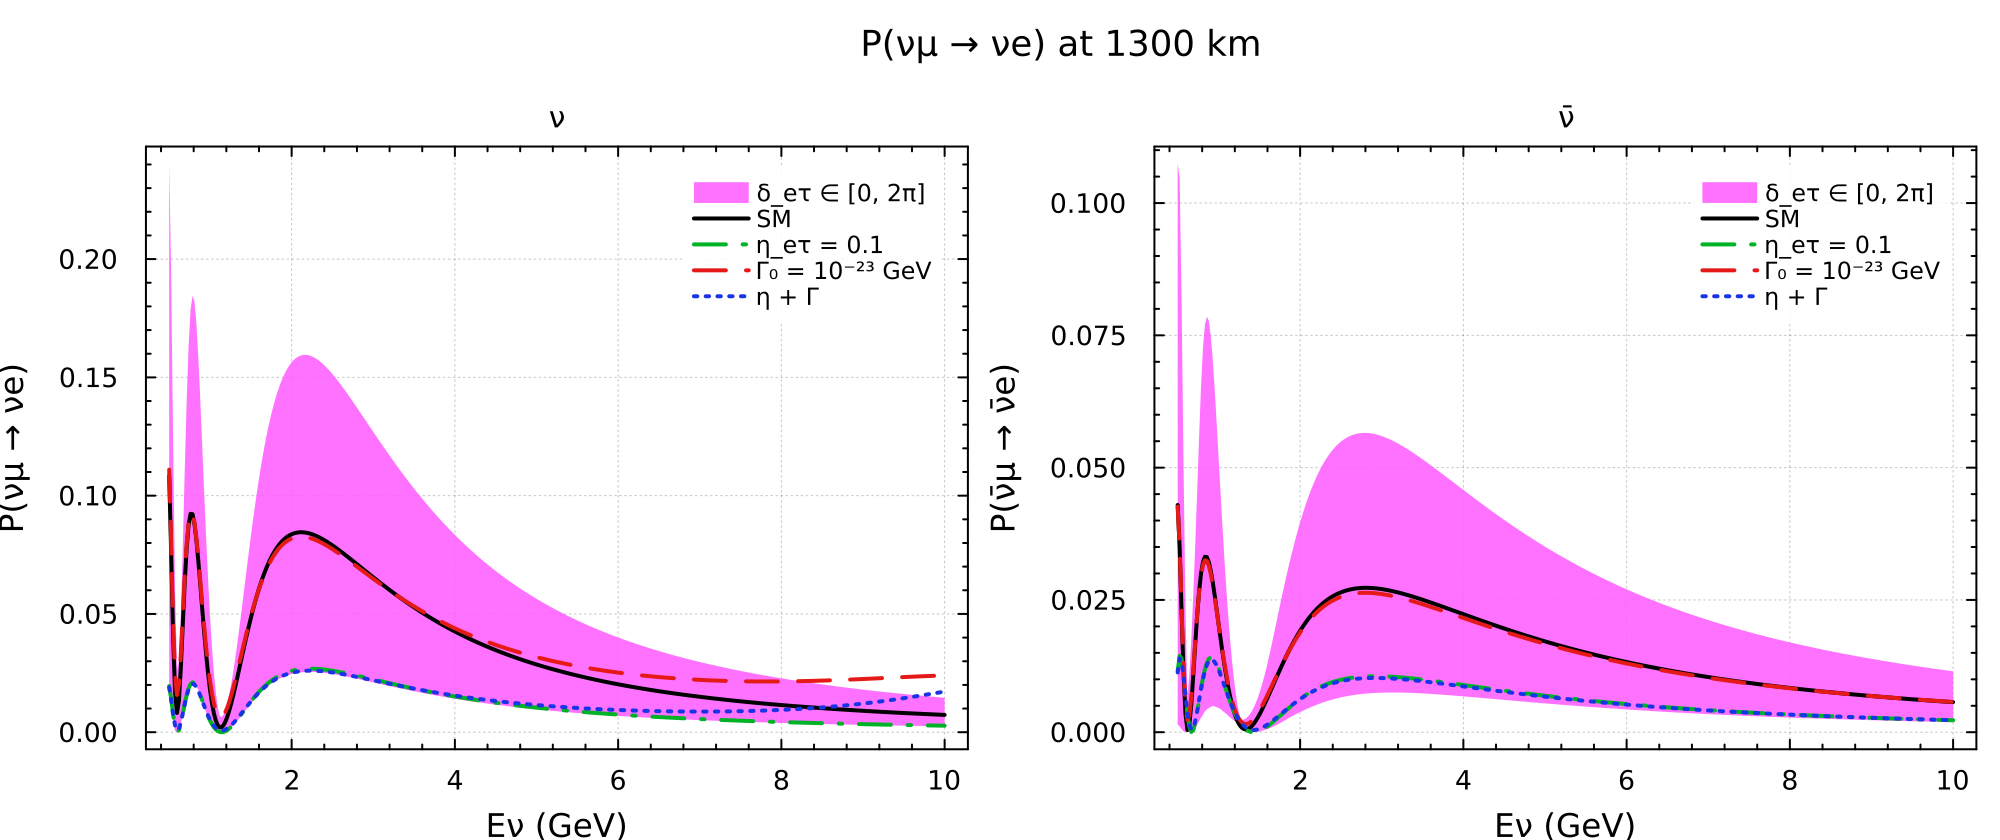

In [8]:
panel(anti) = plot_probability("SM" => sm, "η_eτ = 0.1" => nsi, "Γ₀ = 10⁻²³ GeV" => deco, "η + Γ" => both;
    E = range(0.5, 10, 400), L = 1300, ρ = 2.848, antineutrino = anti,
    bands = ("δ_eτ ∈ [0, 2π]" => (nsi, :δ_eτ => range(0, 2π, 37)),))
plot_grid([panel(false) panel(true)]; title = "P(νμ → νe) at 1300 km", column_titles = ("ν", "ν̄"), size = (1000, 420))

The effective mixing parameters in matter, from the numerical diagonalisation of the Hamiltonian:

In [9]:
effective_parameters(model, sm; E = 2.5, ρ = 2.848)

OscParams
  θ12 = 1.50276  (sin²θ12 = 0.995378)
  θ13 = 0.189392  (sin²2θ13 = 0.136745)
  θ23 = 0.857109  (sin²θ23 = 0.571465)
  δ   = 3.4557  (1.1 π)
  Δm21 = 0.00050428 eV²
  Δm31 = 0.00247817 eV²
  ρ   = 1.0

In [10]:
effective_parameters(model, nsi; E = 2.5, ρ = 2.848)

OscParams
  θ12 = 1.56739  (sin²θ12 = 0.999988)
  θ13 = 0.1115  (sin²2θ13 = 0.0489101)
  θ23 = 0.870297  (sin²θ23 = 0.584491)
  δ   = 3.64115  (1.159 π)
  Δm21 = 0.000513882 eV²
  Δm31 = 0.00241287 eV²
  ρ   = 1.0

## Running `Run.m`

`run_model` runs everything that `Run.m` lists: the calculations, the plots and the LaTeX report.

In [11]:
results = run_model(snsi_dir; output = mktempdir())
results.calculations[4]   # Calculate[[4]]: P(νμ → νe) at 1, 2.5 and 5 GeV with η_eτ = 0.1 and Γ₀ = 10⁻²³ GeV

Effective mixing matrix (E = 2.5 GeV, ρ = 2.848 g/cm³):
3×3 Matrix{ComplexF64}:
 0.0103969-0.000486176im   -0.570332+0.813221im   -0.0725658+0.0895466im
 -0.719363+0.0090618im    -0.0842679+0.0124295im    0.689292-0.00743782im
  0.694497+0.0im          -0.0783399-0.0im          0.715218+0.0im

Effective masses squared in eV² (E = 2.5 GeV, ρ = 2.848 g/cm³):
3-element Vector{Float64}:
 3.618187883458323e-5
 0.0005495889278548257
 0.0024580432798307758

Effective parameters (E = 2.5 GeV, ρ = 2.848 g/cm³):
OscParams
  θ12 = 1.50142  (sin²θ12 = 0.995195)
  θ13 = 0.191175  (sin²2θ13 = 0.139205)
  θ23 = 0.754863  (sin²θ23 = 0.469484)
  δ   = 3.61286  (1.15 π)
  Δm21 = 0.000503941 eV²
  Δm31 = 0.00248682 eV²
  ρ   = 1.0

P(μ → e) at L = 1300.0 km (E = [1.0, 2.5, 5.0] GeV, ρ = 2.848 g/cm³):
3-element Vector{Float64}:
 0.005470290919721274
 0.023351950381050646
 0.010313694447619093

Plot[Pmue] written to pmue.pdf
LaTeX written to SNSI.tex


("P(μ → e) at L = 1300.0 km (E = [1.0, 2.5, 5.0] GeV, ρ = 2.848 g/cm³)", [0.005470290919721274, 0.023351950381050646, 0.010313694447619093], "\\[ P(\\nu_{μ} \\to \\nu_{e}) = \\left(0.00547, 0.02335, 0.01031\\right) \\quad (L = 1300\\,\\mathrm{km}) \\quad (E = 1\\,\\mathrm{GeV}, \\rho = 2.848\\,\\mathrm{g/cm^3}) \\]")

## DUNE

This is the DUNE configuration of the Technical Design Report. Like the C analysis, it runs for 5 years in neutrino mode and 5 in antineutrino mode.

In [12]:
use_model!(model)   # run_model leaves the model's engine on; set it again to be explicit
dune = Experiment(dune_configuration())   # the first time, this downloads the data tables from arXiv
running_time!(dune, 5.0)   # years, each beam mode

Experiment "DUNE_GLoBES" (/root/.julia/scratchspaces/367f8d2e-8d77-4eed-9bd4-73b32ac618fb/dune/DUNE_GLoBES.glb)
  baseline     1284.9 km
  target mass  40.0 kt
  energy bins  80 from 0 to 110 GeV
  channels     32
  rules        nue_app, nuebar_app, numu_dis, numubar_dis

In [13]:
for (label, p) in ("SM" => sm, "η_eτ = 0.1" => nsi, "Γ₀ = 10⁻²³ GeV" => deco)
    simulate!(p)
    println(rpad(label, 16), round.(Int, [sum(event_rates(dune; rule = r).signal) for r in 1:4]), "   (", join(rule_names(dune), ", "), ")")
end

SM              [1793, 393, 15521, 9083]   (nue_app, nuebar_app, numu_dis, numubar_dis)
η_eτ = 0.1      [588, 145, 15987, 9273]   (nue_app, nuebar_app, numu_dis, numubar_dis)
Γ₀ = 10⁻²³ GeV  [1838, 409, 15739, 9145]   (nue_app, nuebar_app, numu_dis, numubar_dis)


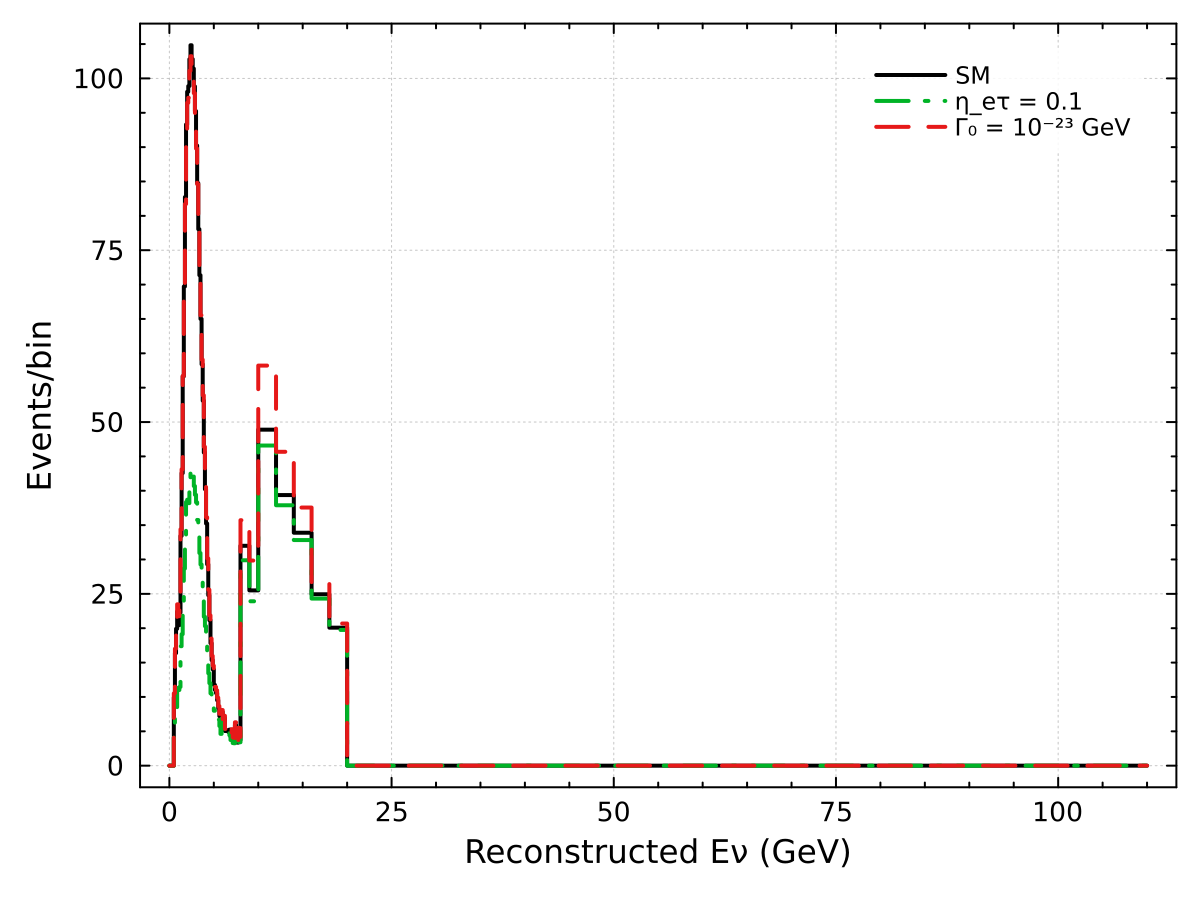

In [14]:
plot_events(dune, "SM" => sm, "η_eτ = 0.1" => nsi, "Γ₀ = 10⁻²³ GeV" => deco; rule = 1)   # νe appearance

## Mass ordering and CP violation

The significance $\sqrt{\Delta\chi^2}$ of the wrong mass ordering, and of CP conservation, as a function of the true $\delta_{CP}$. The fit varies $\theta_{23}$, $\delta_{CP}$ and $\Delta m^2_{31}$, and also $\eta_{e\tau}$ when the true $\eta_{e\tau}$ is not zero. $\Gamma_0$ keeps its true value. The systematics are the correlated normalisation errors of the DUNE configuration.

Each point takes about 45 s, so these two cells take about half an hour. Use fewer points in `δ_true` for a quicker look.

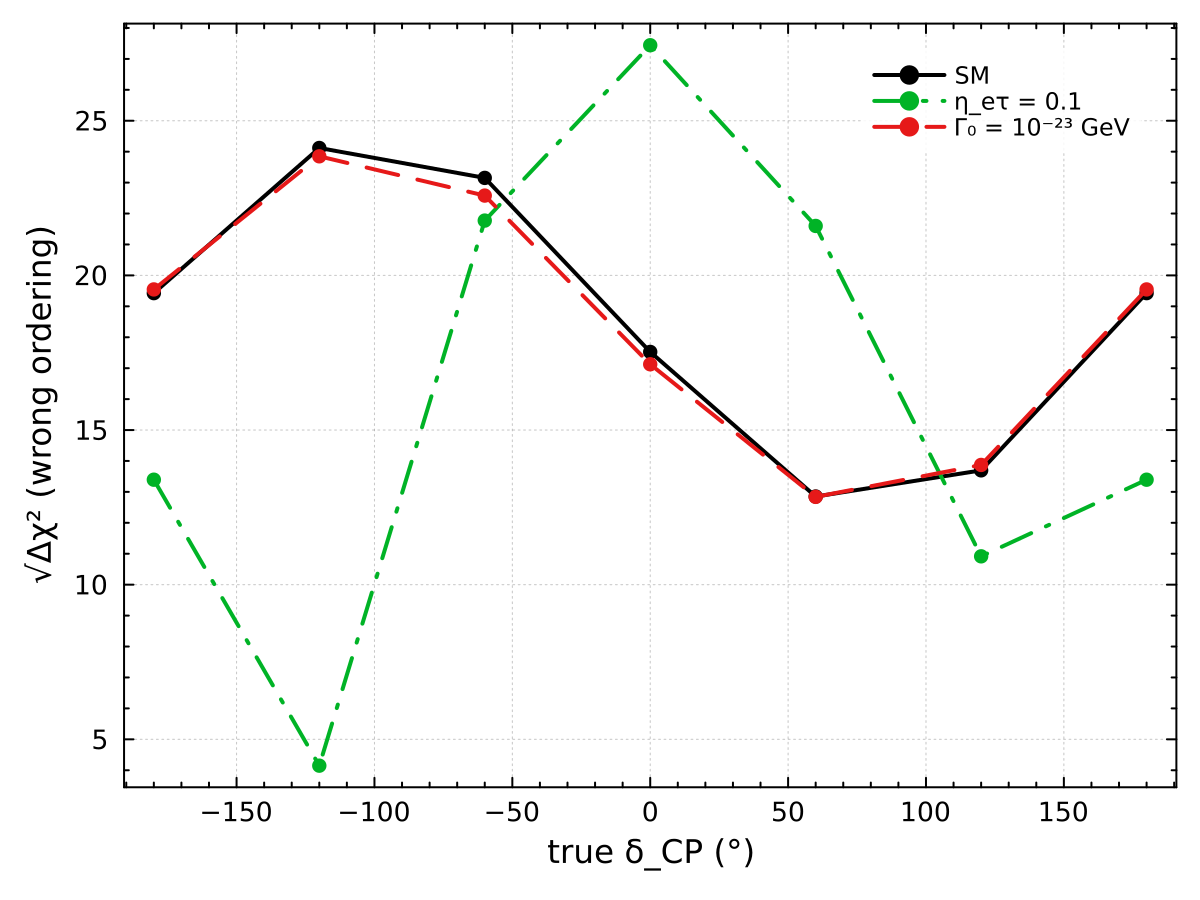

In [15]:
δ_true = range(-π, π, 7)
scenarios = ("SM" => (sm, (:θ23, :δ, :Δm31)), "η_eτ = 0.1" => (nsi, (:θ23, :δ, :Δm31, :η_eτ)), "Γ₀ = 10⁻²³ GeV" => (deco, (:θ23, :δ, :Δm31)))
mo = [label => mass_ordering_sensitivity(truth, δ_true; free) for (label, (truth, free)) in scenarios]
plot_curves(rad2deg.(δ_true), mo...; xlabel = "true δ_CP (°)", ylabel = "√Δχ² (wrong ordering)", markers = true)

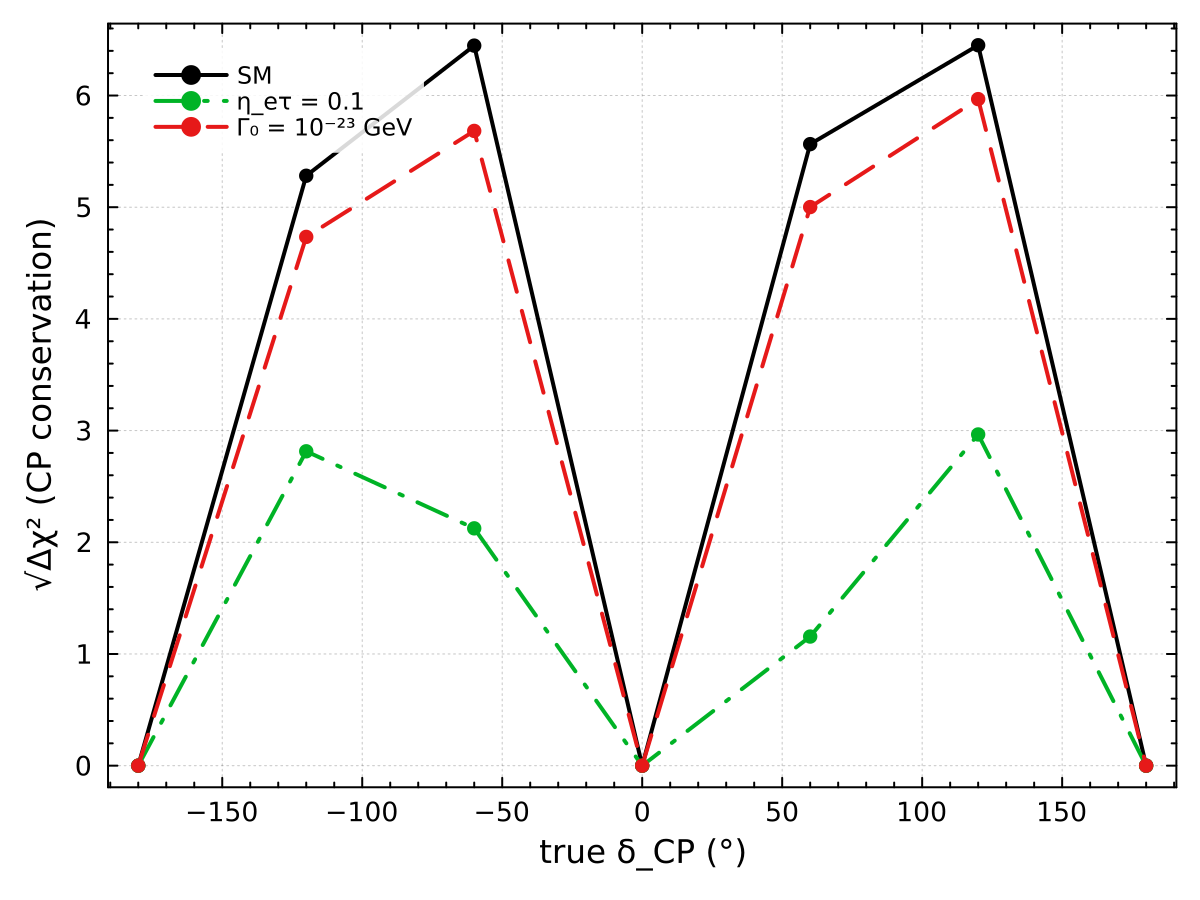

In [16]:
cpv = [label => cp_violation_sensitivity(truth, δ_true; free = filter(!=(:δ), free)) for (label, (truth, free)) in scenarios]
plot_curves(rad2deg.(δ_true), cpv...; xlabel = "true δ_CP (°)", ylabel = "√Δχ² (CP conservation)", markers = true)

## How well DUNE measures $\eta_{e\tau}$

The data are simulated without new physics. Each test value of $\eta_{e\tau}$ is fitted over $\theta_{23}$, $\delta_{CP}$ and $\Delta m^2_{31}$.

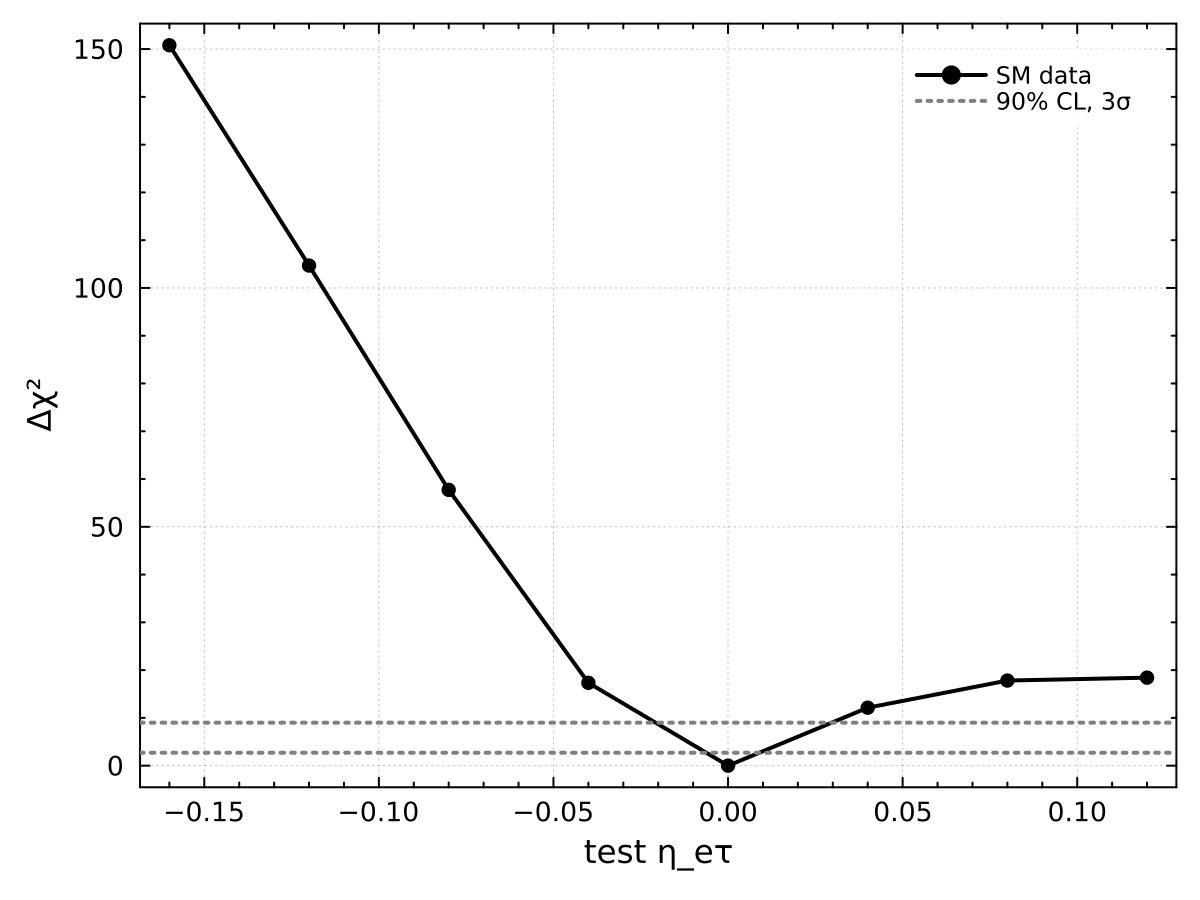

In [17]:
η = range(-0.16, 0.12, 8)
χ² = chi2_profile(sm, :η_eτ => η; free = (:θ23, :δ, :Δm31))
plot_curves(η, "SM data" => χ²; xlabel = "test η_eτ", ylabel = "Δχ²", markers = true)
hline!([2.71, 9]; color = :gray, linestyle = :dot, label = "90% CL, 3σ")

## The model in LaTeX

In [18]:
print(latex(model; NuFit = false))

\section{The Scalar NSI with decoherence model}
Model by GLoBES.jl example.

Flavours: $\nu_e, \nu_\mu, \nu_\tau$ (3 states). Energies, masses and the Hamiltonian are in eV; $A = \sqrt{2} G_F N_e$ is the matter potential.

\subsection*{Effective Hamiltonian}
\begin{equation}
  H = \frac{1}{2E} M M^\dagger + H_{\mathrm{Matter}}
\end{equation}
For antineutrinos $H \to H^*$ with $A \to -A$.

\subsection*{Definitions}
\begin{align}
  \eta &= \begin{pmatrix} \eta_{ee} & \eta_{e\mu} e^{i \delta_{e\mu}} & \eta_{e\tau} e^{i \delta_{e\tau}} \\ \eta_{e\mu} e^{-i \delta_{e\mu}} & \eta_{\mu\mu} & \eta_{\mu\tau} e^{i \delta_{\mu\tau}} \\ \eta_{e\tau} e^{-i \delta_{e\tau}} & \eta_{\mu\tau} e^{-i \delta_{\mu\tau}} & \eta_{\tau\tau} \end{pmatrix} \\
  R_{12} &= R_{12}\left(\theta_{12}\right) \\
  R_{13} &= R_{13}\left(\theta_{13}\right) \\
  R_{23} &= R_{23}\left(\theta_{23}\right) \\
  U_\delta &= P_{3}\left(\delta_{\mathrm{CP}}\right)
\end{align}
\subsection*{Mixing matrix}
\begin{align}
  U &= R_{2

In [ ]:
standard_engine!()   # back to standard three-flavour oscillations